# 02 · Exploração e teste da hipótese

**Hipótese:** crime e preço de imóvel têm correlação negativa, ou seja, bairro mais violento, metro quadrado mais barato.

In [1]:
import gzip
import json
import ssl
import urllib.request
from urllib.error import URLError

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

from comum import (
    AQUA, AZUL, CACHE, DIVERGENTE, FORMATO_REAIS, LARANJA, MEDIDAS_CRIME, MUDO, SUPERFICIE, TINTA2,
    contexto_https, em_unicos, grupo_crime, normaliza_bairro, perfil_por_unidade,
)

crimes = pd.read_parquet(CACHE / "crimes_sp.parquet")
itbi = pd.read_parquet(CACHE / "itbi_sp.parquet")

print(f"crimes    {len(crimes):>9,} ocorrências")
print(f"itbi      {len(itbi):>9,} transações")

crimes    2,214,258 ocorrências
itbi      1,302,804 transações


### Estilo dos gráficos

Paleta fixa nos três notebooks:
- Azul = série única; laranja/aqua só com mais de uma série, ordem fixa.
- Magnitude: rampa de uma cor (nunca arco-íris — sem ordem perceptual).
- Crime e preço: rampas diferentes (azul/laranja), pra não confundir escalas.
- Polaridade (correlação, −1 a +1): divergente azul↔vermelho, cinza no meio.

In [2]:
# Paleta, rcParams e FORMATO_REAIS vêm de comum.py; aqui só as rampas usadas neste notebook.
RAMPA_CRIME = LinearSegmentedColormap.from_list("crime", ["#cde2fb", "#5598e7", "#256abf", "#0d366b"])
RAMPA_PRECO = LinearSegmentedColormap.from_list("preco", ["#fde8dc", "#f29b70", "#eb6834", "#8f3414"])
ESCADA_AZUL = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]

sns.set_palette([AZUL, LARANJA, AQUA])

## 1 · Deflacionando para reais constantes

- Base cobre 2022–2026; sem corrigir inflação, parte da variação de preço seria só IPCA.
- Fonte: **IPCA oficial**, API do IBGE (tabela 1737) — número-índice (2266) e variação mensal (63). Salvo em `ipca_ibge.csv`.
- Fator = índice do mês de referência ÷ índice do mês da transação (não encadeia variações arredondadas — acumula erro).
- Verificação: IPCA anual por dois caminhos independentes (razão de índices × produto de variações) — se concordam, a série foi lida certo.

In [3]:
URL_IPCA = (
    "https://servicodados.ibge.gov.br/api/v3/agregados/1737"
    "/periodos/202101-202612/variaveis/2266|63?localidades=N1[all]"
)
ARQUIVO_IPCA = CACHE / "ipca_ibge.csv"
VARIAVEIS_IPCA = {"2266": "indice", "63": "variacao_pct"}


def baixa_ipca():
    pedido = urllib.request.Request(URL_IPCA, headers={"Accept-Encoding": "identity"})
    try:
        with urllib.request.urlopen(pedido, timeout=60, context=contexto_https()) as resposta:
            conteudo = resposta.read()
    except URLError as erro:
        if isinstance(erro.reason, ssl.SSLCertVerificationError):
            raise RuntimeError(
                "A conexão HTTPS não confiou no certificado da rede. Configure "
                "GEOSAMPA_CA_BUNDLE com o caminho do certificado CA confiável da rede "
                "e execute novamente. A verificação SSL não foi desativada."
            ) from erro
        raise
    if conteudo[:2] == b"\x1f\x8b":
        conteudo = gzip.decompress(conteudo)
    bruto = json.loads(conteudo.decode("utf-8"))
    series = {
        VARIAVEIS_IPCA[v["id"]]: v["resultados"][0]["series"][0]["serie"] for v in bruto
    }
    return pd.DataFrame(series).rename_axis("periodo").reset_index()


def carrega_ipca():
    if ARQUIVO_IPCA.exists():
        print(f"IPCA: lendo de {ARQUIVO_IPCA.name}")
        tabela = pd.read_csv(ARQUIVO_IPCA, dtype={"periodo": str})
    else:
        tabela = baixa_ipca()
        tabela.to_csv(ARQUIVO_IPCA, index=False)
        print(f"IPCA: baixado da API do IBGE (tabela 1737) e salvo em {ARQUIVO_IPCA.name}")
    for coluna in VARIAVEIS_IPCA.values():
        tabela[coluna] = pd.to_numeric(tabela[coluna], errors="coerce")
    tabela["mes"] = tabela["periodo"].str[:4] + "-" + tabela["periodo"].str[4:]
    return tabela.dropna(subset=["indice"]).sort_values("mes").reset_index(drop=True)


ipca = carrega_ipca()
ipca["fator"] = ipca["indice"].iloc[-1] / ipca["indice"]
MES_REFERENCIA = ipca["mes"].iloc[-1]

print(f"Série oficial: {len(ipca)} meses, de {ipca['mes'].iloc[0]} a {MES_REFERENCIA}")
print(f"Reais constantes de: {MES_REFERENCIA}")
print(f"Fator no mês mais antigo ({ipca['mes'].iloc[0]}): {ipca['fator'].iloc[0]:.4f}\n")

anual = ipca.assign(ano=ipca["mes"].str[:4]).groupby("ano").agg(
    meses=("variacao_pct", "size"),
    indice_dez=("indice", "last"),
    por_encadeamento=("variacao_pct", lambda v: ((1 + v / 100).prod() - 1) * 100),
)
anual["por_numero_indice"] = (anual["indice_dez"] / anual["indice_dez"].shift() - 1) * 100
anual["diferença"] = anual["por_encadeamento"] - anual["por_numero_indice"]

anual[["meses", "por_encadeamento", "por_numero_indice", "diferença"]].style.format(
    {"por_encadeamento": "{:.2f}%", "por_numero_indice": "{:.2f}%", "diferença": "{:+.3f} pp"},
    na_rep="—",
).set_caption("IPCA acumulado por ano, calculado de duas formas independentes")

IPCA: lendo de ipca_ibge.csv
Série oficial: 69 meses, de 2021-01 a 2026-09
Reais constantes de: 2026-09
Fator no mês mais antigo (2021-01): 1.3805



,meses,por_encadeamento,por_numero_indice,diferença
ano,,,,
2021,12,10.06%,—,—
2022,12,5.78%,5.79%,-0.000 pp
2023,12,4.62%,4.62%,-0.000 pp
2024,12,4.83%,4.83%,+0.000 pp
2025,12,4.26%,4.26%,+0.000 pp
2026,9,3.95%,3.95%,-0.000 pp


## 2 · Agrupando as 24 naturezas criminais

- 24 naturezas → 4 grupos: trânsito/culposo, patrimonial sem violência (furto), violento (roubo, com vítima), outros.
- Ordem importa: trânsito/culposo capturado **primeiro** (senão "homicídio"/"lesão corporal" no nome contaria como violência).
- Eixo da análise: furto mede fluxo de gente; roubo mede risco.

In [4]:
# grupo_crime (comum.py) testa trânsito/culposo primeiro, depois furto, depois violento.
crimes["grupo"] = em_unicos(crimes["natureza"].astype(str), grupo_crime)

(
    crimes.groupby(["grupo", "natureza"], observed=True)
    .size()
    .rename("ocorrências")
    .reset_index()
    .sort_values(["grupo", "ocorrências"], ascending=[True, False])
    .set_index(["grupo", "natureza"])
)

ocorrências
grupo                     natureza                                                    
outros                    TRAFICO DE ENTORPECENTES                               22998
                          PORTE DE ENTORPECENTES                                  4247
                          APREENSAO DE ENTORPECENTES                              4014
                          PORTE DE ARMA                                           3883
patrimonial sem violência FURTO - OUTROS                                       1129990
                          FURTO DE VEICULO                                      187010
                          FURTO DE CARGA                                           680
trânsito / culposo        LESAO CORPORAL CULPOSA POR ACIDENTE DE TRANSITO        62539
                          LESAO CORPORAL CULPOSA - OUTRAS                         2756
                          HOMICIDIO CULPOSO POR ACIDENTE DE TRANSITO              2655
                          LESAO CORPORAL CULPOSA  OUTRAS                           674
                          HOMICIDIO CULPOSO OUTROS                                 115
                          HOMICIDIO DOLOSO POR ACIDENTE DE TRANSITO                 39
violento                  ROUBO - OUTROS                                        534361
                          LESAO CORPORAL DOLOSA                                 170581
                          ROUBO DE VEICULO                                       58276
                          ROUBO DE CARGA                                         10649
                          ESTUPRO DE VULNERAVEL                                   9224
                          ESTUPRO                                                 3331
                          TENTATIVA DE HOMICIDIO                                  3145
                          HOMICIDIO DOLOSO                                        2277
                          EXTORSAO MEDIANTE SEQUESTRO                              452
                          LATROCINIO                                               217
                          LESAO CORPORAL SEGUIDA DE MORTE                          130
                          ROUBO A BANCO                                             15

## 3 · Localizando cada transação

A localização usa duas fontes, nesta ordem: bairro do ITBI normalizado e reconhecido na base de crimes; para os registros restantes, o bairro modal entre transações com o mesmo CEP. As coordenadas atribuídas são o centro mediano das ocorrências do bairro, portanto representam o bairro, não o endereço da venda.

| fonte | cobertura nesta execução | papel |
|---|---:|---|
| Bairro do ITBI reconhecido | 38,4% | Mantém o bairro informado quando válido |
| Fallback por CEP | +55,5 p.p. | Preenche bairros ausentes ou não reconhecidos |
| **bairro resolvido** | **94,0%** | 6,0% das transações permanecem sem bairro |
| Coordenada de bairro disponível | 93,7% | Centro mediano das ocorrências com coordenada |

Os percentuais dependem dos caches e devem ser atualizados ao reexecutar a preparação ou substituir os dados de entrada.

In [5]:
VOCABULARIO_BAIRROS = set(crimes["bairro"].dropna().astype(str))


def localiza(transacoes):
    """Bairro do ITBI quando reconhecido nos crimes; senão, o bairro mais frequente do mesmo CEP."""
    tabela = transacoes.copy()
    bairro = em_unicos(tabela["bairro_itbi"], normaliza_bairro)
    tabela["bairro"] = bairro.where(bairro.isin(VOCABULARIO_BAIRROS))
    cobertura_itbi = tabela["bairro"].notna().mean()

    cep = tabela["cep"].astype("Int64").astype("string").str.zfill(8)
    modal_por_cep = (  # bairro mais frequente de cada CEP (pares com nulo são descartados)
        tabela.assign(cep=cep)
        .groupby(["cep", "bairro"])
        .size()
        .sort_values()
        .reset_index()
        .groupby("cep")["bairro"]
        .last()
    )
    por_cep = cep.map(modal_por_cep)
    acrescentado_por_cep = tabela["bairro"].isna() & por_cep.notna()
    tabela["bairro"] = tabela["bairro"].fillna(por_cep)

    centros = (
        crimes.dropna(subset=["lat", "lon"])
        .groupby("bairro", observed=True)[["lat", "lon"]]
        .median()
    )
    centros.index = centros.index.astype(str)
    tabela = tabela.join(centros, on="bairro")

    cobertura = {
        "bairro ITBI válido": cobertura_itbi,
        "bairro acrescentado por CEP": acrescentado_por_cep.mean(),
        "bairro resolvido": tabela["bairro"].notna().mean(),
        "coordenada disponível": tabela["lat"].notna().mean(),
    }
    return tabela, cobertura


itbi, cobertura_bairro = localiza(itbi)

print(f"bairro localizado em {cobertura_bairro['bairro resolvido']:.1%} das transações")
print(f"coordenada central do bairro disponível em {cobertura_bairro['coordenada disponível']:.1%} das transações\n")
pd.Series(cobertura_bairro, name="cobertura").to_frame().style.format({"cobertura": "{:.1%}"})

bairro localizado em 94.0% das transações
coordenada central do bairro disponível em 93.7% das transações



,cobertura
bairro ITBI válido,38.4%
bairro acrescentado por CEP,55.5%
bairro resolvido,94.0%
coordenada disponível,93.7%


## 4 · Filtros: de guia de ITBI a preço real por metro quadrado

- **2022–2026**: escrituras vêm desde 1994; sem crime pra comparar antes de 2022 (0,7% das linhas saem).
- **Proporção transmitida = 100%**: abaixo disso é fração ideal de lote-matriz — área construída seria do prédio inteiro, não do imóvel vendido. Filtro mais caro (~metade).
- **Exclui vaga de garagem**: infla o R$/m² do bairro.
- **Mês coberto pelo IPCA**: meses recentes sem índice ainda são descartados, não estimados.

In [6]:
MESES_COM_IPCA = set(ipca["mes"])

FILTROS = [
    ("guias de ITBI (tudo)", lambda d: d),
    ("transação entre 2022 e 2026", lambda d: d[d["ano"].between(2022, 2026)]),
    ("natureza = compra e venda", lambda d: d[d["natureza_transacao"].astype(str).str.startswith("1.")]),
    ("100% do imóvel transmitido", lambda d: d[d["proporcao_transmitida"] == 100]),
    ("padrão residencial", lambda d: d[d["padrao_desc"].astype(str).str.startswith("RESIDENCIAL")]),
    ("exclui vaga de garagem", lambda d: d[~d["uso_desc"].astype(str).str.contains("GARAGEM")]),
    ("área construída e valor > 0", lambda d: d[d["area_construida"].gt(0) & d["valor_transacao"].gt(0)]),
    ("bairro identificado", lambda d: d[d["bairro"].notna()]),
    ("mês coberto pela série do IPCA", lambda d: d[d["mes"].isin(MESES_COM_IPCA)]),
]

base = itbi
funil = []
for nome, filtro in FILTROS:
    base = filtro(base)
    funil.append((nome, len(base)))

base = base.merge(ipca[["mes", "fator"]], on="mes", how="left")

base["valor_real"] = base["valor_transacao"] * base["fator"]
base["preco_m2_nominal"] = base["valor_transacao"] / base["area_construida"]
base["preco_m2"] = base["valor_real"] / base["area_construida"]

base = base[base["preco_m2"].between(*base["preco_m2"].quantile([0.01, 0.99]))]
funil.append(("R$/m² real entre os percentis 1 e 99", len(base)))

base["idade"] = base["ano"] - base["acc"].where(base["acc"].between(1800, 2026))

assert base["fator"].notna().all(), "transação sem fator de deflação"
assert base["bairro"].notna().all(), "transação sem bairro"

funil = pd.DataFrame(funil, columns=["filtro", "linhas"])
funil["% do total"] = funil["linhas"] / funil.loc[0, "linhas"]
funil["perda no passo"] = funil["linhas"].diff().fillna(0)
funil.style.format({
    "linhas": "{:,.0f}", "% do total": "{:.1%}", "perda no passo": "{:,.0f}",
}).hide(axis="index")

filtro,linhas,% do total,perda no passo
guias de ITBI (tudo),"1,302,804",100.0%,0
transação entre 2022 e 2026,"1,011,321",77.6%,"-291,483"
natureza = compra e venda,"909,590",69.8%,"-101,731"
100% do imóvel transmitido,"498,283",38.2%,"-411,307"
padrão residencial,"438,939",33.7%,"-59,344"
exclui vaga de garagem,"402,197",30.9%,"-36,742"
área construída e valor > 0,"402,196",30.9%,-1
bairro identificado,"378,244",29.0%,"-23,952"
mês coberto pela série do IPCA,"378,244",29.0%,0
R$/m² real entre os percentis 1 e 99,"370,678",28.5%,"-7,566"


### Quanto a deflação muda o retrato

Nominal mistura valorização real com inflação; a série deflacionada isola o que sobrou em poder de compra.

Variação do R$/m² mediano de 2022-01 a 2026-01:
  nominal ....... +32.6%
  real (IPCA) ... +9.8%


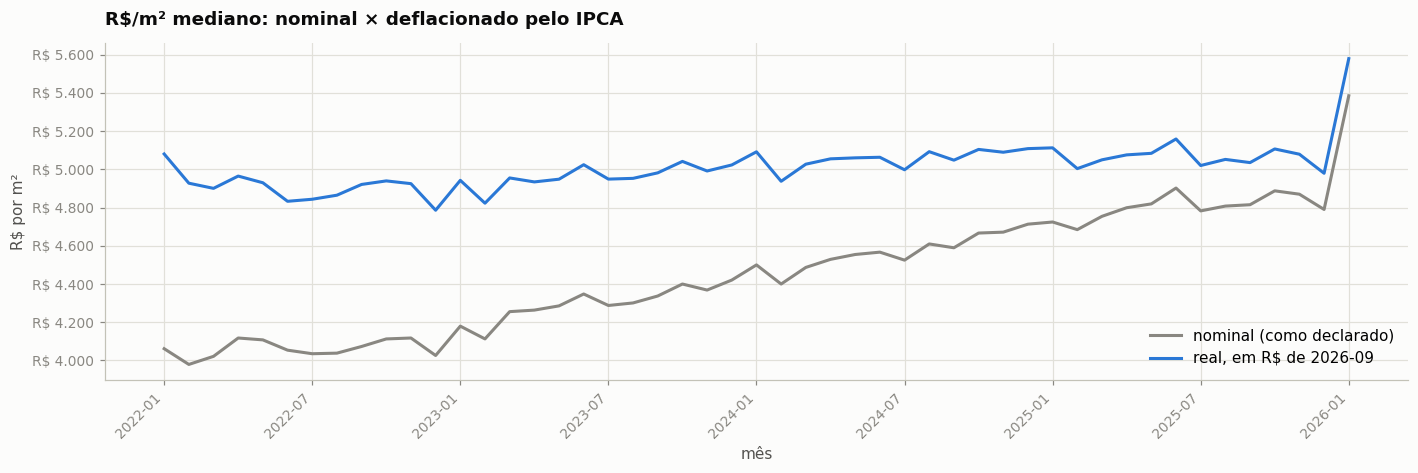

In [7]:
comparativo = base.groupby("mes").agg(nominal=("preco_m2_nominal", "median"),
                                      real=("preco_m2", "median"))

fig, eixo = plt.subplots(figsize=(13, 4.4))
eixo.plot(comparativo.index, comparativo["nominal"], color=MUDO, label="nominal (como declarado)")
eixo.plot(comparativo.index, comparativo["real"], color=AZUL,
          label=f"real, em R$ de {MES_REFERENCIA}")
eixo.set(title="R$/m² mediano: nominal × deflacionado pelo IPCA", xlabel="mês", ylabel="R$ por m²")
eixo.yaxis.set_major_formatter(FORMATO_REAIS)
eixo.set_xticks(eixo.get_xticks()[::6])
plt.setp(eixo.get_xticklabels(), rotation=45, ha="right")
eixo.legend(loc="lower right")
plt.tight_layout()

primeiro, ultimo = comparativo.index[0], comparativo.index[-1]
variacao = comparativo.loc[[primeiro, ultimo]].pct_change().iloc[-1] * 100
print(f"Variação do R$/m² mediano de {primeiro} a {ultimo}:")
print(f"  nominal ....... {variacao['nominal']:+.1f}%")
print(f"  real (IPCA) ... {variacao['real']:+.1f}%")

**`preco_m2` daqui em diante é sempre o valor real.**

## 5 · O lado imóvel

Sanidade antes da correlação: distribuição do preço, estabilidade do volume no tempo, preço por tipo de imóvel.

count    370,678
mean       5,514
std        2,771
min           33
25%        3,652
50%        5,015
75%        6,802
max       19,281


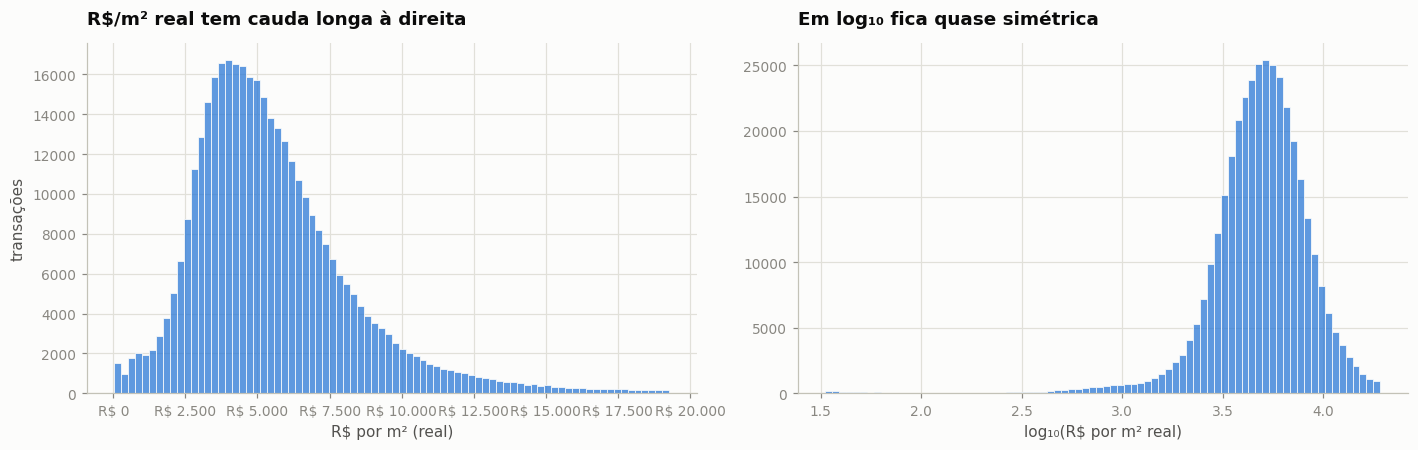

In [8]:
fig, (esq, drt) = plt.subplots(1, 2, figsize=(13, 4.2))

sns.histplot(base["preco_m2"], bins=80, color=AZUL, ax=esq, edgecolor=SUPERFICIE, linewidth=0.5)
esq.set(title="R$/m² real tem cauda longa à direita", xlabel="R$ por m² (real)", ylabel="transações")
esq.xaxis.set_major_formatter(FORMATO_REAIS)

sns.histplot(np.log10(base["preco_m2"]), bins=80, color=AZUL, ax=drt, edgecolor=SUPERFICIE, linewidth=0.5)
drt.set(title="Em log₁₀ fica quase simétrica", xlabel="log₁₀(R$ por m² real)", ylabel="")

plt.tight_layout()

print(base["preco_m2"].describe().apply(lambda v: f"{v:,.0f}").to_string())

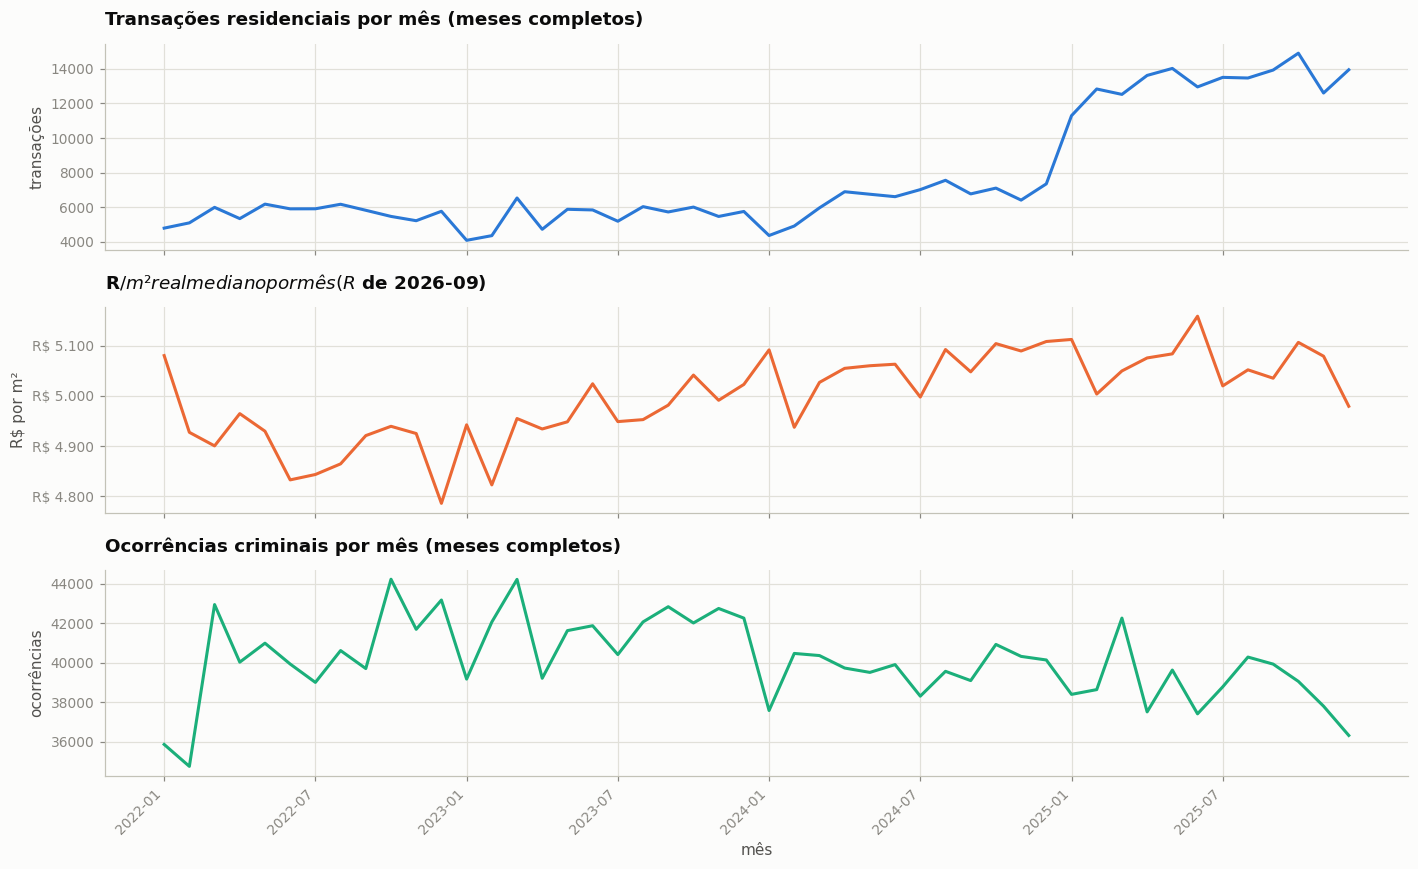

In [9]:
mes_incompleto = base["data_transacao"].max().to_period("M").strftime("%Y-%m")
base_meses_completos = base[base["mes"] < mes_incompleto]
crimes_meses_completos = crimes[crimes["mes"] < mes_incompleto]

por_mes = base_meses_completos.groupby("mes").agg(
    transacoes=("preco_m2", "size"), preco_mediano=("preco_m2", "median")
)
crimes_mes = crimes_meses_completos.groupby("mes").size()

fig, eixos = plt.subplots(3, 1, figsize=(13, 8), sharex=True)

eixos[0].plot(por_mes.index, por_mes["transacoes"], color=AZUL)
eixos[0].set(title="Transações residenciais por mês (meses completos)", ylabel="transações")

eixos[1].plot(por_mes.index, por_mes["preco_mediano"], color=LARANJA)
eixos[1].set(title=f"R$/m² real mediano por mês (R$ de {MES_REFERENCIA})", ylabel="R$ por m²")
eixos[1].yaxis.set_major_formatter(FORMATO_REAIS)

eixos[2].plot(crimes_mes.index, crimes_mes.to_numpy(), color=AQUA)
eixos[2].set(title="Ocorrências criminais por mês (meses completos)", ylabel="ocorrências", xlabel="mês")

eixos[2].set_xticks(eixos[2].get_xticks()[::6])
plt.setp(eixos[2].get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()

- Os gráficos mensais exibem apenas meses completos; o último mês parcial é removido automaticamente. As taxas anuais de crime usam 2022–2025, anos completos.

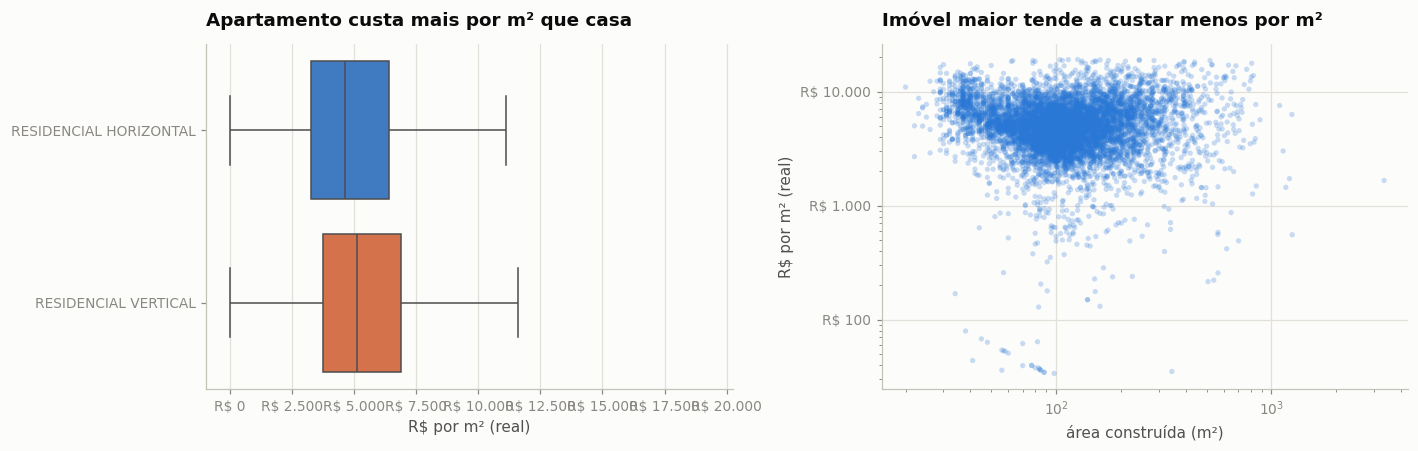

In [10]:
base["tipo"] = base["padrao_desc"].astype(str).str.strip()
recorte = base[base["tipo"].isin(base["tipo"].value_counts().index[:2])]

fig, (esq, drt) = plt.subplots(1, 2, figsize=(13, 4.2))

sns.boxplot(data=recorte, y="tipo", x="preco_m2", hue="tipo", palette=[AZUL, LARANJA],
            legend=False, fliersize=0, linewidth=1, ax=esq)
esq.set(title="Apartamento custa mais por m² que casa", xlabel="R$ por m² (real)", ylabel="")
esq.xaxis.set_major_formatter(FORMATO_REAIS)

sns.scatterplot(data=base.sample(8000, random_state=42), x="area_construida", y="preco_m2",
                color=AZUL, alpha=0.25, s=12, edgecolor="none", ax=drt)
drt.set(title="Imóvel maior tende a custar menos por m²", xlabel="área construída (m²)",
        ylabel="R$ por m² (real)", xscale="log", yscale="log")
drt.yaxis.set_major_formatter(FORMATO_REAIS)

plt.tight_layout()

## 6 · O lado crime

Qual é a composição das ocorrências e onde elas se concentram.

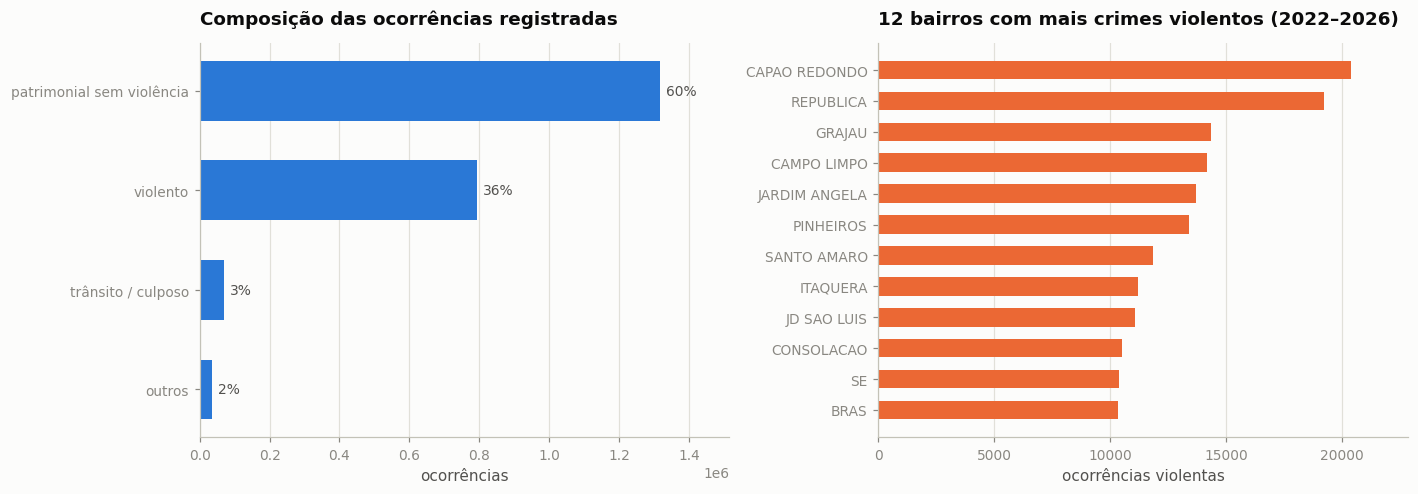

In [11]:
fig, (esq, drt) = plt.subplots(1, 2, figsize=(13, 4.6))

por_grupo = crimes["grupo"].value_counts()
barras = esq.barh(por_grupo.index[::-1], por_grupo.to_numpy()[::-1], color=AZUL, height=0.6)
esq.bar_label(barras, labels=[f"{v / len(crimes):.0%}" for v in por_grupo.to_numpy()[::-1]],
              padding=4, color=TINTA2, fontsize=9)
esq.set(title="Composição das ocorrências registradas", xlabel="ocorrências")
esq.margins(x=0.15)
esq.grid(axis="y", visible=False)

top = crimes[crimes["grupo"] == "violento"]["bairro"].value_counts().head(12)
drt.barh(top.index[::-1].astype(str), top.to_numpy()[::-1], color=LARANJA, height=0.6)
drt.set(title="12 bairros com mais crimes violentos (2022–2026)", xlabel="ocorrências violentas")
drt.margins(x=0.12)
drt.grid(axis="y", visible=False)

plt.tight_layout()

Bairros do topo são polos comerciais com grande circulação — contagem bruta mede **exposição**, não só risco. Por isso a seção 8 testa 4 medidas, não só a contagem.

## 7 · Os dois mapas

- Esquerda: densidade de ocorrências criminais geolocalizadas (escala log).
- Direita: mediana do R$/m² por hexágono, calculada nas transações com bairro identificado.
- As coordenadas das vendas são centros medianos dos bairros; o mapa de preço mostra padrões entre bairros, não a localização exata dos imóveis. Janeiro de 2026 é parcial e tem poucas transações.

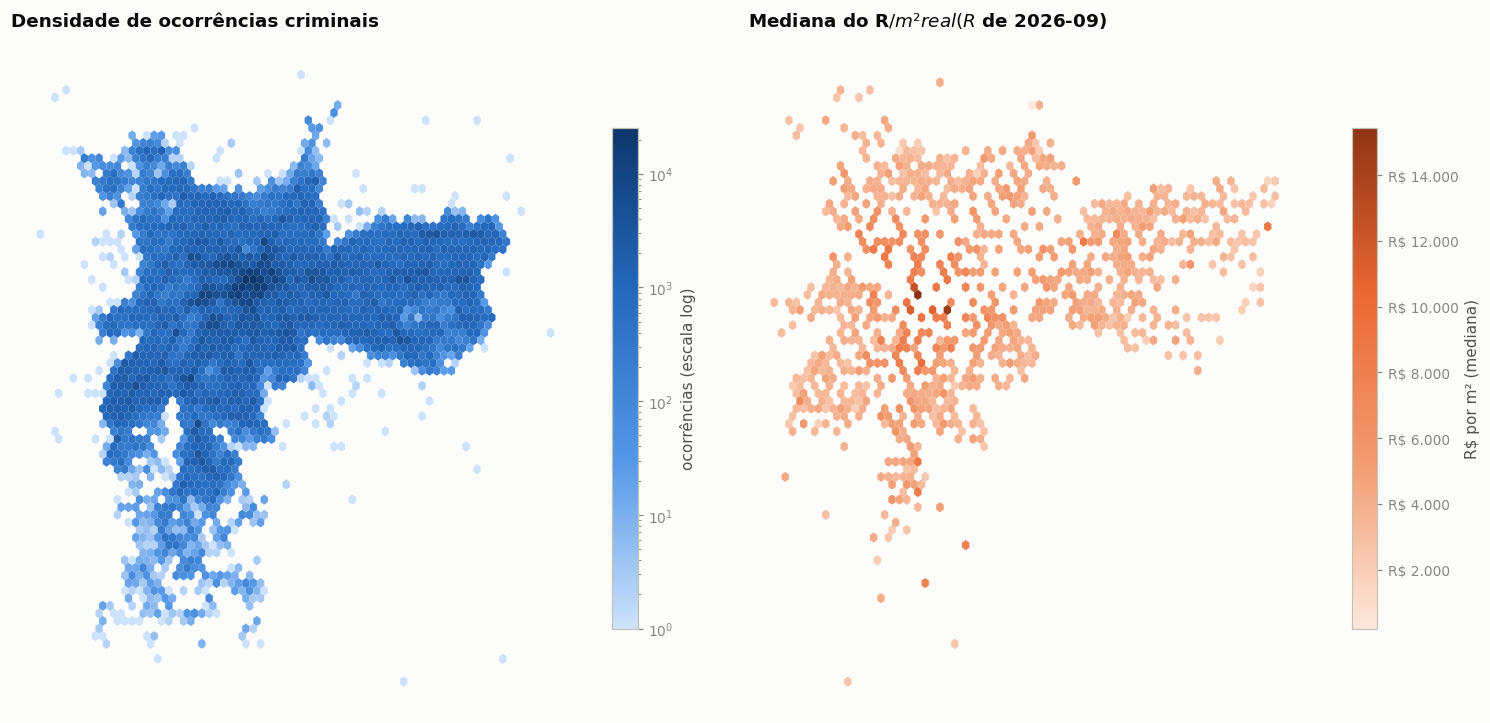

In [12]:
geo_crimes = crimes.dropna(subset=["lat", "lon"])
geo_base = base.dropna(subset=["lat", "lon"])

fig, (esq, drt) = plt.subplots(1, 2, figsize=(14, 6.5))

mapa_crime = esq.hexbin(geo_crimes["lon"], geo_crimes["lat"], gridsize=70,
                        bins="log", cmap=RAMPA_CRIME, linewidths=0)
esq.set_title("Densidade de ocorrências criminais")
fig.colorbar(mapa_crime, ax=esq, shrink=0.75, label="ocorrências (escala log)")

mapa_preco = drt.hexbin(geo_base["lon"], geo_base["lat"], C=geo_base["preco_m2"],
                        reduce_C_function=np.median, mincnt=10, gridsize=70,
                        cmap=RAMPA_PRECO, linewidths=0)
drt.set_title(f"Mediana do R$/m² real (R$ de {MES_REFERENCIA})")
fig.colorbar(mapa_preco, ax=drt, shrink=0.75, label="R$ por m² (mediana)", format=FORMATO_REAIS)

for eixo in (esq, drt):
    eixo.set(xticks=[], yticks=[], aspect="equal")
    eixo.grid(visible=False)
    for borda in eixo.spines.values():
        borda.set_visible(False)

plt.tight_layout()

## 8 · Agregando por bairro

Bairro: grande o bastante para ter crime e transações, pequeno o bastante pra ter perfil próprio. Preço já em reais constantes → mediana comparável entre bairros.

Quatro medidas de crime:

| medida | o que mede | fraqueza |
|---|---|---|
| crimes totais / ano | volume absoluto | contaminada por fluxo |
| crimes violentos / ano | volume do que assusta | idem, menos |
| % de crimes violentos | **composição** | ignora o nível |
| violentos por mil transações | ajustado pelo estoque | aproximação grosseira de população |

- Se as quatro convergem, resultado é robusto; se divergem, a divergência é informativa.
- Descarta bairros com < 30 transações ou < 30 ocorrências (ruído). `log₁₀(1+x)` evita `-inf`.

In [13]:
# perfil_por_unidade (comum.py): crime = média anual de 2022–2025; exige ≥ 30 transações e ≥ 30 crimes/ano.
bairros = perfil_por_unidade(base, crimes, "bairro")

print(f"{len(bairros)} bairros aprovados, cobrindo {bairros['n_transacoes'].sum():,} transações")
bairros.sort_values("preco_m2_mediano", ascending=False).head(8)[
    ["preco_m2_mediano", "n_transacoes", "crimes_total", "violentos", "share_violento"]
].round(2)

424 bairros aprovados, cobrindo 325,771 transações


,preco_m2_mediano,n_transacoes,crimes_total,violentos,share_violento
bairro,,,,,
JARDIM EUROPA,15439.63,169,92.50,29.75,0.32
JARDIM PAULISTANO,12403.29,201,844.25,151.25,0.18
VILA NOVA CONCEICAO,10833.16,1411,636.00,194.25,0.31
ITAIM BIBI,9507.52,1791,7085.00,2173.00,0.31
JARDINS,9455.42,106,97.50,21.00,0.22
CIDADE JARDIM,9039.51,242,180.75,61.00,0.34
VILA OLIMPIA,8709.74,2695,772.75,301.25,0.39
JARDIM AMERICA,8694.78,2962,117.75,32.50,0.28


## 9 · O teste da hipótese

- Dois cenários: completo, e sem os 7 bairros do centro comercial (fluxo gigante, estoque residencial pequeno) — testa se a correlação é artefato de movimento.
- Pearson (linear) e Spearman (só ordem) — Spearman é o mais confiável, imune a outlier.

In [14]:
CENTRO_COMERCIAL = ["SE", "REPUBLICA", "BOM RETIRO", "BRAS", "SANTA IFIGENIA", "LUZ", "CAMPOS ELISEOS"]

CENARIOS = {
    "completo": bairros,
    "sem o centro comercial": bairros.drop(index=CENTRO_COMERCIAL, errors="ignore"),
}


def correlacao(dados, coluna):
    pearson = stats.pearsonr(dados[coluna], dados["preco_m2_mediano"])
    spearman = stats.spearmanr(dados[coluna], dados["preco_m2_mediano"])
    return {
        "Pearson r": pearson.statistic,
        "p (Pearson)": pearson.pvalue,
        "Spearman ρ": spearman.statistic,
        "p (Spearman)": spearman.pvalue,
        "bairros": len(dados),
    }


resultados = pd.DataFrame(
    [
        {"cenário": cenario, "medida de crime": medida, **correlacao(dados, coluna)}
        for cenario, dados in CENARIOS.items()
        for medida, coluna in MEDIDAS_CRIME.items()
    ]
).set_index(["cenário", "medida de crime"])

resultados.style.format({
    "Pearson r": "{:+.3f}", "Spearman ρ": "{:+.3f}",
    "p (Pearson)": "{:.2e}", "p (Spearman)": "{:.2e}",
}).background_gradient(cmap=DIVERGENTE, vmin=-0.6, vmax=0.6, subset=["Pearson r", "Spearman ρ"])

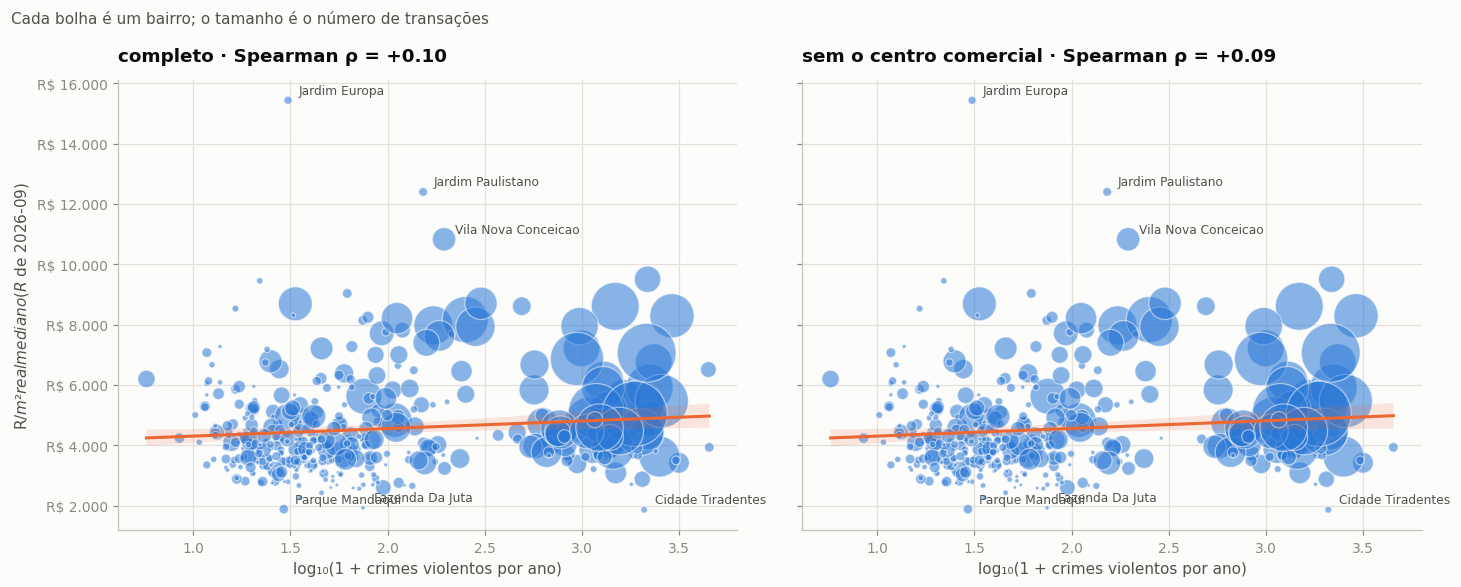

In [15]:
fig, eixos = plt.subplots(1, 2, figsize=(13.5, 5.4), sharey=True)

for eixo, (cenario, dados) in zip(eixos, CENARIOS.items()):
    sns.regplot(
        data=dados, x="log_violentos", y="preco_m2_mediano", ax=eixo,
        scatter_kws={"s": dados["n_transacoes"] / 6, "alpha": 0.55, "color": AZUL,
                     "linewidths": 0.8, "edgecolor": SUPERFICIE},
        line_kws={"color": LARANJA, "linewidth": 2},
    )
    rho = stats.spearmanr(dados["log_violentos"], dados["preco_m2_mediano"]).statistic
    eixo.set(title=f"{cenario} · Spearman ρ = {rho:+.2f}",
             xlabel="log₁₀(1 + crimes violentos por ano)", ylabel="")
    destaques = [*dados["preco_m2_mediano"].nlargest(3).index, *dados["preco_m2_mediano"].nsmallest(3).index]
    for bairro in destaques:
        linha = dados.loc[bairro]
        eixo.annotate(bairro.title(), (linha["log_violentos"], linha["preco_m2_mediano"]),
                      xytext=(7, 4), textcoords="offset points", fontsize=8, color=TINTA2)

eixos[0].set_ylabel(f"R$/m² real mediano (R$ de {MES_REFERENCIA})")
eixos[0].yaxis.set_major_formatter(FORMATO_REAIS)
fig.suptitle("Cada bolha é um bairro; o tamanho é o número de transações",
             x=0.01, ha="left", color=TINTA2, fontsize=10)
plt.tight_layout()

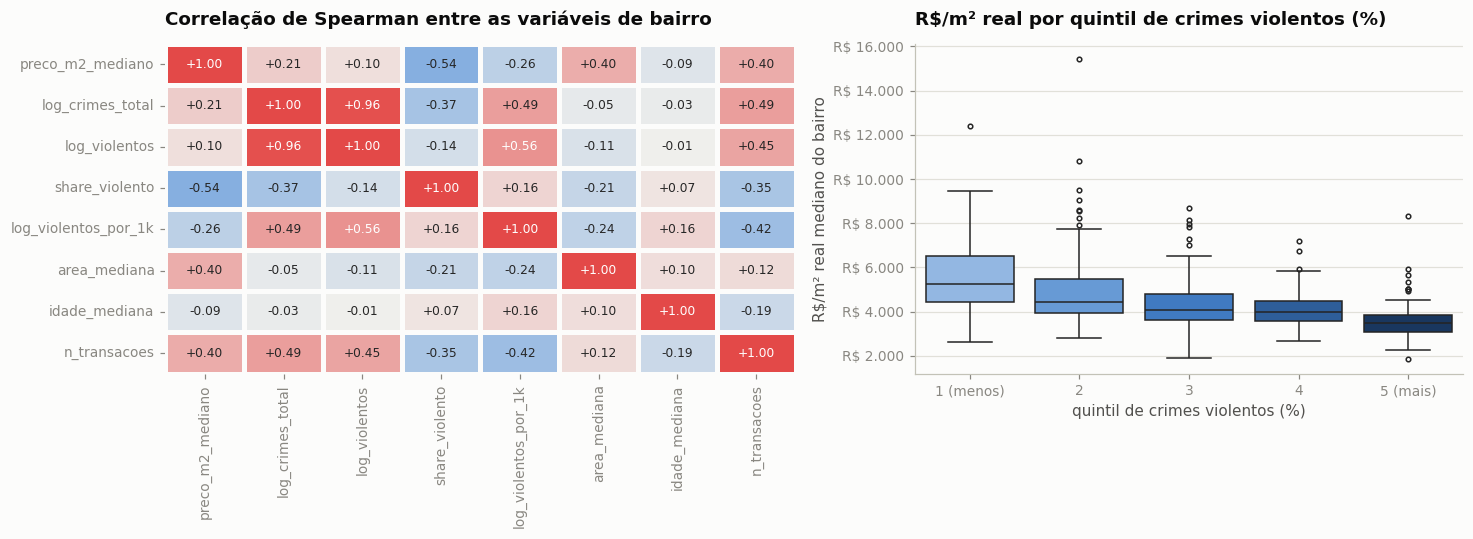

In [16]:
fig, (esq, drt) = plt.subplots(1, 2, figsize=(13.5, 5), width_ratios=[1.15, 1])

colunas = ["preco_m2_mediano", "log_crimes_total", "log_violentos", "share_violento",
           "log_violentos_por_1k", "area_mediana", "idade_mediana", "n_transacoes"]
sns.heatmap(bairros[colunas].corr(method="spearman"), cmap=DIVERGENTE, vmin=-1, vmax=1,
            annot=True, fmt="+.2f", annot_kws={"size": 8}, linewidths=2,
            linecolor=SUPERFICIE, cbar=False, ax=esq)
esq.set_title("Correlação de Spearman entre as variáveis de bairro")

quintis = pd.qcut(bairros["share_violento"], 5, labels=["1 (menos)", "2", "3", "4", "5 (mais)"])
sns.boxplot(x=quintis, y=bairros["preco_m2_mediano"], hue=quintis, palette=ESCADA_AZUL,
            legend=False, fliersize=3, linewidth=1, ax=drt)
drt.set(title="R$/m² real por quintil de crimes violentos (%)",
        xlabel="quintil de crimes violentos (%)", ylabel="R$/m² real mediano do bairro")
drt.yaxis.set_major_formatter(FORMATO_REAIS)

plt.tight_layout()

### O que os números dizem

Nesta execução, a base agrega **424 bairros** e 325.771 transações antes dos demais passos de modelagem. A composição das ocorrências apresenta associação negativa com o preço; a contagem bruta, não:

| medida de crime | Spearman ρ | p-valor | leitura |
|---|---:|---:|---|
| crimes totais / ano | +0,210 | 1,34×10⁻⁵ | associação positiva fraca |
| crimes violentos / ano | +0,095 | 0,050 | associação fraca, limítrofe |
| **% de crimes violentos** | **−0,538** | **3,93×10⁻³³** | associação negativa forte |
| violentos por mil transações | −0,263 | 3,88×10⁻⁸ | associação negativa moderada |

Essas correlações são descritivas; não demonstram que violência cause preços menores.

| quintil de % violento | R$/m² mediano |
|---|---:|
| 1 (menos) | R$ 5.243 |
| 2 | R$ 4.440 |
| 3 | R$ 4.062 |
| 4 | R$ 3.983 |
| 5 (mais) | **R$ 3.505** |

A mediana do quintil mais violento é cerca de 33% menor que a do menos violento; há sobreposição entre as distribuições, então não é uma regra para cada bairro.

- Jardim Paulistano: 844 ocorrências/ano, R$ 12,4 mil/m², 18% violentas. Cidade Tiradentes: 3.976/ano, R$ 1,9 mil/m², 52% violentas.
- Sem os sete bairros do centro comercial, a correlação da proporção violenta muda de −0,538 para −0,543.
- Os resultados são desta execução e devem ser recalculados após mudanças nos dados, filtros ou método de localização.

## 10 · Base para a modelagem

Perfil criminal do bairro (média 2022–2025, estático — hipótese é espacial, não temporal) colado em cada transação. `base_modelagem.parquet` e `bairros.parquet` gravados pro notebook 03 não repetir tratamento.

In [17]:
COLUNAS_CRIME = ["crimes_total", "violentos", "share_violento", "violentos_por_1k"]

modelagem = base.merge(bairros[COLUNAS_CRIME], left_on="bairro", right_index=True, how="inner")
modelagem.attrs["mes_referencia"] = MES_REFERENCIA
modelagem.to_parquet(CACHE / "base_modelagem.parquet", index=False)
bairros.to_parquet(CACHE / "bairros.parquet")
(CACHE / "mes_referencia.txt").write_text(MES_REFERENCIA, encoding="utf-8")

print(f"base_modelagem: {len(modelagem):,} transações × {modelagem.shape[1]} colunas")
print(f"bairros:        {len(bairros):,} bairros")
print(f"preços em reais constantes de {MES_REFERENCIA}")

base_modelagem: 325,771 transações × 40 colunas
bairros:        424 bairros
preços em reais constantes de 2026-09


## 11 · Ressalvas

- **Crime registrado ≠ crime ocorrido.** A propensão a registrar pode variar entre bairros e afetar as comparações.
- **Contagem mede exposição, não só risco.** Não há população por bairro disponível para calcular taxas por habitante.
- **Localização dos imóveis:** 94,0% dos registros recebem bairro pelo campo reconhecido do ITBI ou pelo modal do CEP. O restante é excluído da análise por bairro; não há preenchimento por nome de rua.
- **Coordenadas aproximadas:** latitude e longitude das transações são centros medianos das ocorrências criminais do bairro. Servem para visualização agregada, não para indicar o imóvel vendido.
- **Preço autodeclarado** — incentivo a subdeclarar. Se a subdeclaração variar por tipo de bairro, pode enviesar a comparação.
- **Correlação não é causalidade.** Renda e outras características podem explicar parte da associação. O notebook 03 controla por atributos do imóvel, mas não é um experimento.
- IPCA é índice nacional; não mede especificamente a dinâmica imobiliária de São Paulo.

➡️ Próximo: `03_modelagem.ipynb`.